We study 100 Chinese A-share companies from the list chosen by our group. Our question is clear: does stock selection with Value, Profitability and Momentum help, and does machine learning improve how we divide money between these three factors? We compare equal stock weights, equal factor weights and model-based factor weights. We use monthly decisions and the same trading costs for every strategy.

In [1]:
from pathlib import Path
import contextlib
import io
import logging
import warnings
import math
import hashlib
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.dates import AutoDateLocator, ConciseDateFormatter
import torch
from torch import nn
from prophet import Prophet
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import balanced_accuracy_score
from xgboost import XGBRegressor
from IPython.display import display

In [2]:
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'inputs/china_factor_100').is_dir())
INPUTS = ROOT / 'inputs/china_factor_100'
RESULTS = ROOT / 'results/china_factor_100'
RESULTS.mkdir(parents=True, exist_ok=True)
pd.options.display.float_format = '{:,.3f}'.format
plt.rcParams.update({'figure.figsize': (11, 5), 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.2})
logging.getLogger('cmdstanpy').setLevel(logging.ERROR)
logging.getLogger('prophet').setLevel(logging.ERROR)

companies = pd.read_csv(INPUTS / 'stocks.csv', dtype={'code': str})
price_rows = pd.read_csv(INPUTS / 'prices.csv', dtype={'code': str}, parse_dates=['date'])
financials = pd.read_csv(INPUTS / 'financials.csv', dtype={'code': str}, parse_dates=['period', 'notice_date', 'available_date'])
share_rows = pd.read_csv(INPUTS / 'shares.csv', dtype={'code': str}, parse_dates=['effective_date', 'notice_date', 'available_date'])
companies['is_financial'] = companies.is_financial.astype(str).str.lower().isin(['true', '1', 'yes'])
financials['usable'] = financials.usable.astype(str).str.lower().isin(['true', '1', 'yes'])
financials['balance_usable'] = financials.balance_usable.astype(str).str.lower().isin(['true', '1', 'yes'])
STOCKS = companies.code.tolist()
if len(STOCKS) != 100 or len(set(STOCKS)) != 100:
    raise ValueError('We need 100 different six-digit company codes.')
if not companies.code.str.fullmatch(r'[0-9]{6}').all():
    raise ValueError('Check the stock codes.')
if price_rows.duplicated(['code', 'date']).any():
    raise ValueError('A stock has more than one price on the same date.')
if not set(price_rows.code).issubset(STOCKS):
    raise ValueError('A price belongs to a company outside the list.')
calendar = pd.DatetimeIndex(pd.read_csv(ROOT / 'inputs/china_benchmark/market_calendar.csv', parse_dates=['date']).date)
calendar = calendar[(calendar >= price_rows.date.min()) & (calendar <= price_rows.date.max())]
price_rows = price_rows.loc[price_rows.date.isin(calendar)].copy()
observed = price_rows.pivot(index='date', columns='code', values='adjusted_close').reindex(index=calendar, columns=STOCKS)
raw_observed = price_rows.pivot(index='date', columns='code', values='raw_close').reindex(index=calendar, columns=STOCKS)
volumes = price_rows.pivot(index='date', columns='code', values='volume').reindex(index=calendar, columns=STOCKS)
observed = observed.where(observed.gt(0))
raw_observed = raw_observed.where(raw_observed.gt(0))
tradable = observed.notna() & raw_observed.notna() & volumes.gt(0)
prices = observed.ffill()
raw_prices = raw_observed.ffill()
first_quote_dates = {}
for stock in STOCKS:
    first_quote_dates[stock] = observed[stock].first_valid_index()
first_quotes = pd.Series(first_quote_dates)
first_quotes.index.name = observed.columns.name
finance_by_code = {stock: rows.sort_values(['period', 'available_date']) for stock, rows in financials.groupby('code')}
shares_by_code = {stock: rows.sort_values(['effective_date', 'available_date']) for stock, rows in share_rows.groupby('code')}
company_info = companies.set_index('code')
daily_returns = prices.pct_change(fill_method=None)
if observed.stack().le(0).any():
    raise ValueError('Prices must be positive.')
source_files = pd.DataFrame([{'file': file.name, 'sha256': hashlib.sha256(file.read_bytes()).hexdigest()} for file in INPUTS.glob('*.csv')])
source_files.to_csv(RESULTS / 'input_files.csv', index=False)
display(companies[['code', 'name_en', 'name_zh', 'listing_date', 'is_financial']])

,code,name_en,name_zh,listing_date,is_financial
0,002371,"NAURA Technology Group Co.,Ltd.",北方華創,2010-03-16,False
1,002422,"Sichuan Kelun Pharmaceutical Co., Ltd.",科倫藥業,2010-06-03,False
2,601728,China Telecom Corporation Limited,中國電信,2021-08-20,False
3,600276,"Jiangsu Hengrui Pharmaceuticals Co.,Ltd.",恒瑞醫藥,2000-10-18,False
4,600519,"Kweichow Moutai Co.,Ltd.",貴州茅臺,2001-08-27,False
...,...,...,...,...,...
95,000338,"Weichai Power Co., Ltd.",濰柴動力,2007-04-30,False
96,688008,"Montage Technology Co., Ltd.",瀾起科技,2019-07-22,False
97,600150,China CSSC Holdings Limited,中國船舶,1998-05-20,False
98,601127,"Seres Group Co.,Ltd.",賽力斯,2016-06-15,False


We use EastMoney for annual company accounts and historical share counts. Daily prices come from Tencent. We use the adjusted close to measure returns and the raw close to calculate market value. We use the A-share price to value all ordinary company shares. We then add funded debt and minority equity and subtract cash to estimate enterprise value. The portfolio itself holds only the A-share security. The price adjustment is the provider's return proxy; we do not build a separate dividend cash account. We use the later of the report announcement and 30 June after the financial year. Share counts must also be known and effective by the decision date. This gives us a clear data rule for every month. Saved financial records can contain later revisions, and our company list was chosen today. The test is a historical study of this selected group.

In [3]:
FACTORS = ['Value', 'Profitability', 'Momentum']
MIN_ELIGIBLE = 12
MIN_QUOTE_COUNT = 160
STALE_REPORT_MONTHS = 18
TOP_FRACTION = 0.25

month_signals = calendar.to_series().groupby(calendar.to_period('M')).last()
month_signals = pd.DatetimeIndex(month_signals)
score_tables = {}
baskets = {}
all_score_rows = []

for signal in month_signals:
    rows = []
    one_month = signal - pd.DateOffset(months=1)
    twelve_months = signal - pd.DateOffset(months=12)

    for stock in STOCKS:
        result = {
            'signal': signal,
            'code': stock,
            'eligible': False,
            'reason': '',
            'Value': np.nan,
            'Profitability': np.nan,
            'Momentum': np.nan,
            'Book to market': np.nan,
            'EBIT to book equity': np.nan,
            'Ordinary momentum': np.nan,
        }

        if company_info.loc[stock, 'is_financial']:
            result['reason'] = 'Financial business'
        elif not bool(tradable.loc[signal, stock]):
            result['reason'] = 'No trading quote on the decision date'
        elif pd.isna(first_quotes[stock]) or first_quotes[stock] > twelve_months:
            result['reason'] = 'Less than twelve months of price history'
        else:
            accounts = finance_by_code.get(stock, pd.DataFrame())
            known_shares = shares_by_code.get(stock, pd.DataFrame())

            if len(accounts):
                accounts = accounts.loc[accounts.available_date.le(signal)]
                accounts = accounts.sort_values(['period', 'available_date'])
                accounts = accounts.drop_duplicates('period', keep='last')
            if len(known_shares):
                known_shares = known_shares.loc[
                    known_shares.available_date.le(signal)
                    & known_shares.effective_date.le(signal)
                ]

            if accounts.empty:
                result['reason'] = 'No available annual accounts'
            elif known_shares.empty:
                result['reason'] = 'No available total share count'
            else:
                current = accounts.iloc[-1]
                prior = accounts.loc[accounts.period.eq(current.period - pd.DateOffset(years=1))]

                if not bool(current.usable):
                    result['reason'] = 'Incomplete EBIT or capital fields'
                elif prior.empty or not bool(prior.iloc[-1].balance_usable):
                    result['reason'] = 'No complete opening capital'
                elif signal > current.period + pd.DateOffset(months=STALE_REPORT_MONTHS):
                    result['reason'] = 'Annual accounts are more than eighteen months old'
                else:
                    opening = prior.iloc[-1]
                    shares = known_shares.iloc[-1]
                    market_cap = float(raw_prices.loc[signal, stock]) * float(shares.total_shares)
                    enterprise_value = market_cap + current.interest_debt + current.minority_equity - current.cash
                    average_capital = (current.invested_capital + opening.invested_capital) / 2
                    history = daily_returns.loc[twelve_months:signal, stock].dropna()
                    quote_count = int(tradable.loc[twelve_months:signal, stock].sum())
                    volatility = history.std(ddof=1) * np.sqrt(252)
                    one_month_prices = prices.loc[:one_month, stock]
                    twelve_month_prices = prices.loc[:twelve_months, stock]
                    one_month_close = float(one_month_prices.iloc[-1]) if len(one_month_prices) else np.nan
                    twelve_month_close = float(twelve_month_prices.iloc[-1]) if len(twelve_month_prices) else np.nan
                    momentum = one_month_close / twelve_month_close - 1
                    values = [current.ebit, enterprise_value, average_capital, market_cap, volatility, momentum]

                    if not np.isfinite(values).all() or min(enterprise_value, average_capital, market_cap, volatility) <= 0:
                        result['reason'] = 'Invalid factor denominator'
                    elif quote_count < MIN_QUOTE_COUNT:
                        result['reason'] = 'Too few daily trading quotes for momentum'
                    else:
                        result.update({
                            'eligible': True,
                            'reason': 'Available',
                            'Value': current.ebit / enterprise_value,
                            'Profitability': current.ebit / average_capital,
                            'Momentum': momentum / volatility,
                            'Book to market': current.parent_equity / market_cap if current.parent_equity > 0 else np.nan,
                            'EBIT to book equity': current.ebit / current.total_equity if current.total_equity > 0 else np.nan,
                            'Ordinary momentum': momentum,
                            'period': current.period,
                            'available_date': current.available_date,
                            'opening_available_date': opening.available_date,
                            'share_available_date': shares.available_date,
                            'share_effective_date': shares.effective_date,
                            'ebit': current.ebit,
                            'enterprise_value': enterprise_value,
                            'average_capital': average_capital,
                            'market_cap': market_cap,
                            'volatility': volatility,
                        })

        rows.append(result)

    scores = pd.DataFrame(rows).set_index('code')
    all_score_rows.append(scores.reset_index())
    eligible = scores.loc[scores.eligible]

    if len(eligible) >= MIN_ELIGIBLE:
        score_tables[signal] = scores
        count = int(math.ceil(len(eligible) * TOP_FRACTION))
        weights = pd.DataFrame(0.0, index=STOCKS, columns=FACTORS)
        for factor in FACTORS:
            selected = eligible[factor].sort_values(ascending=False, kind='stable').head(count).index
            weights.loc[selected, factor] = 1 / count
        baskets[signal] = weights

score_history = pd.concat(all_score_rows, ignore_index=True)
score_history.to_csv(RESULTS / 'factor_scores.csv', index=False)
eligible_counts = score_history.groupby('signal').eligible.sum().rename('eligible_count')
eligible_counts.to_csv(RESULTS / 'eligible_counts.csv')

if not baskets:
    raise ValueError('No month has enough complete company data.')

used = score_history.loc[score_history.eligible]
for field in ['available_date', 'opening_available_date', 'share_available_date', 'share_effective_date']:
    if not used[field].le(used.signal).all():
        raise ValueError('A factor score uses information from after its decision date.')

display(eligible_counts.tail(12).to_frame())
display(score_tables[max(score_tables)].query('eligible')[FACTORS].head(10))

,eligible_count
signal,
2025-11-28,93
2025-12-31,92
2026-01-30,93
2026-02-27,92
2026-03-31,93
2026-04-30,93
2026-05-29,93
2026-06-30,94
2026-07-31,94


,Value,Profitability,Momentum
code,,,
002371,0.014,0.180,1.245
002422,0.038,0.093,0.374
601728,0.077,0.107,-0.197
600276,0.032,0.412,-1.071
600519,0.070,0.539,-0.544
688981,0.010,0.038,-0.095
300760,0.051,0.387,-1.172
688271,0.024,0.136,-1.029
688111,0.018,0.171,-0.614


We keep all 100 companies in the research list. Our saved prices cover 2015-01-05 to 2026-10-16. The traded factor history starts on 2018-08-01, when the needed financial records are available. Between 90 and 94 companies can enter the factor baskets during the evaluation. The last decision uses 94. We require twelve months of price history with at least 160 observed trading quotes. Value is annual EBIT divided by enterprise value. For Profitability, we divide annual EBIT by the average capital at the start and end of that year. Invested capital is total equity plus interest-bearing debt minus cash. Momentum is the twelve-to-one-month price return divided by annual price volatility. We select the highest quarter for each factor and give these shares equal weights.

In [4]:
INITIAL_VALUE = 100000.0
TRADING_COST = 0.001

entries = {}
for signal in score_tables:
    position = calendar.searchsorted(signal, side='right')
    if position < len(calendar):
        entries[signal] = calendar[position]

first_entry = min(entries.values())
first_position = calendar.get_loc(first_entry)
base_date = calendar[first_position - 1] if first_position > 0 else first_entry
factor_dates = calendar[(calendar >= base_date) & (calendar <= calendar[-1])]
factor_curves = {}

for factor in FACTORS:
    schedule = {}
    for signal, entry in entries.items():
        schedule[entry] = baskets[signal][factor].reindex(STOCKS, fill_value=0).to_numpy(float)

    holdings = np.zeros(len(STOCKS))
    cash = INITIAL_VALUE
    values = []
    previous = None

    for day in factor_dates:
        if previous is not None:
            relative = prices.loc[day].to_numpy(float) / prices.loc[previous].to_numpy(float)
            if not np.isfinite(relative[holdings > 0]).all():
                raise ValueError('A held stock has no valuation price.')
            holdings *= np.where(np.isfinite(relative), relative, 1.0)

        before = cash + holdings.sum()
        if day in schedule:
            target = schedule[day]
            if (target < -1e-12).any() or not np.isclose(target.sum(), 1):
                raise ValueError('Long-only target weights must add to one.')

            can_trade = tradable.loc[day].to_numpy(bool)
            frozen = holdings[~can_trade].sum()
            pool = before - frozen
            positive = target[can_trade]
            ratio = positive / positive.sum() if positive.sum() else np.zeros_like(positive)
            holdings[can_trade] = ratio * max(pool, 0)
            cash = before - holdings.sum()

            if cash < -1e-6:
                raise ValueError('Trading used more money than the portfolio owns.')
            cash = max(cash, 0.0)

        value = cash + holdings.sum()
        if value <= 0 or not np.isfinite(value):
            raise ValueError('The portfolio value is invalid.')

        values.append({'date': day, 'value': value, 'cash': cash})
        previous = day

    curve = pd.DataFrame(values).set_index('date')
    factor_curves[factor] = curve.value

factor_values = pd.DataFrame(factor_curves)
factor_values.to_csv(RESULTS / 'factor_history.csv')

monthly_rows = []
signals = sorted(entries)
for signal, following in zip(signals[:-1], signals[1:]):
    if following.to_period('M') != signal.to_period('M') + 1:
        continue
    entry = entries[signal]
    exit_date = entries[following]
    outcome = factor_values.loc[exit_date] / factor_values.loc[entry] - 1
    monthly_rows.append({'signal': signal, 'entry': entry, 'exit': exit_date, **outcome.to_dict()})

factor_targets = pd.DataFrame(monthly_rows).set_index('signal')
factor_targets.to_csv(RESULTS / 'factor_targets.csv')
display(factor_targets.tail(6))

,entry,exit,Value,Profitability,Momentum
signal,,,,,
2026-03-31,2026-04-01,2026-05-06,0.018,0.104,0.163
2026-04-30,2026-05-06,2026-06-01,-0.024,0.020,-0.028
2026-05-29,2026-06-01,2026-07-01,-0.062,0.012,0.027
2026-06-30,2026-07-01,2026-08-03,0.102,-0.049,-0.172
2026-07-31,2026-08-03,2026-09-01,-0.002,0.015,0.029
2026-08-31,2026-09-01,2026-10-08,-0.032,-0.063,-0.077


We decide after the final trading close of each month and trade at the next trading close. We charge 0.10% on each amount bought or sold, including the first investment. We keep a position when the stock has no trading quote. We use its last known close for the value only. We do not buy or sell it at that old price. The remaining money is shared between the targets that can trade. Any money that cannot be invested stays in cash without interest. We add overlapping stock positions before charging costs. We allow fractional holdings in the backtest. We do not model minimum trading lots or fills at daily price limits.

The factor history follows the baskets that were held at each past date. Each past month uses its own factor basket. We calculate factor forecast targets before trading costs. We then evaluate each whole portfolio after its own costs.

In [5]:
LOOKBACK = 8
RETURN_WINDOWS = (1, 4, 13)
RISK_WINDOW = 13
MIN_TRAINING = 36
VALIDATION_START = pd.Timestamp('2023-01-01')
VALIDATION_END = pd.Timestamp('2024-12-31')
TEST_START = pd.Timestamp('2025-01-01')

sequences = {}
sequence_rows = []
sequence_date_rows = []

for signal in factor_targets.index:
    history = factor_values.loc[:signal]
    weekly = history.groupby(history.index.to_period('W-FRI')).tail(1)
    if len(weekly) < LOOKBACK + max(max(RETURN_WINDOWS), RISK_WINDOW):
        continue

    changes = weekly.pct_change(fill_method=None)
    rows = []
    for index in range(len(weekly) - LOOKBACK, len(weekly)):
        values = {}
        risk_returns = changes.iloc[index - RISK_WINDOW + 1:index + 1]
        for factor in FACTORS:
            for window in RETURN_WINDOWS:
                values[f'{factor}_{window}w'] = weekly[factor].iloc[index] / weekly[factor].iloc[index - window] - 1
            values[f'{factor}_volatility'] = risk_returns[factor].std(ddof=1) * np.sqrt(52)

        correlations = risk_returns.corr().to_numpy()[np.triu_indices(3, 1)]
        values['factor_correlation'] = float(correlations.mean())
        rows.append(values)

    frame = pd.DataFrame(rows, index=weekly.tail(LOOKBACK).index)
    if not np.isfinite(frame.to_numpy()).all():
        continue

    sequences[signal] = frame.to_numpy()
    sequence_rows.append(frame.assign(signal=signal).rename_axis('week').reset_index())
    sequence_date_rows.append({
        'signal': signal,
        'first_input_week': frame.index.min(),
        'last_input_week': frame.index.max(),
    })

sequence_dates = pd.DataFrame(sequence_date_rows).set_index('signal')
sample_signals = pd.DatetimeIndex(sorted(sequences))
samples = factor_targets.loc[sample_signals]
sample_x = np.stack([sequences[signal] for signal in sample_signals])
sample_y = samples[FACTORS].to_numpy()
pd.concat(sequence_rows, ignore_index=True).to_csv(RESULTS / 'sequence_inputs.csv', index=False)

validation_signals = samples.index[samples.entry.ge(VALIDATION_START) & samples.exit.le(VALIDATION_END)]
test_signals = samples.index[samples.entry.ge(TEST_START) & samples.exit.le(calendar[-1])]
run_signals = validation_signals.append(test_signals)

if len(validation_signals) != 23 or len(test_signals) == 0:
    raise ValueError('Check that validation has all 23 completed months and the test has completed holding periods.')
if samples.loc[validation_signals].exit.max() > test_signals.min():
    raise ValueError('Model selection finishes after the first evaluation decision.')
for signal in run_signals:
    count = int(samples.exit.le(signal).sum())
    if count < MIN_TRAINING:
        raise ValueError(f'Only {count} completed training months before {signal.date()}.')

display(pd.DataFrame([
    {
        'part': 'Validation',
        'first_entry': samples.loc[validation_signals].entry.min(),
        'last_exit': samples.loc[validation_signals].exit.max(),
        'months': len(validation_signals),
    },
    {
        'part': 'Evaluation',
        'first_entry': samples.loc[test_signals].entry.min(),
        'last_exit': samples.loc[test_signals].exit.max(),
        'months': len(test_signals),
    },
]))

,part,first_entry,last_exit,months
0,Validation,2023-01-03,2024-12-02,23
1,Evaluation,2025-01-02,2026-10-08,21


We give ten models eight weeks of factor information. Each week has one-, four- and thirteen-week factor returns, thirteen-week volatility and the average correlation between factors. The LSTM and CNN read these weeks in order. The other models receive the same values as one row. Prophet uses earlier completed monthly factor returns instead. It gives us a separate time-series comparison.

We keep time in order. A training return must finish before the decision date, so the model cannot learn from a return that is still happening. We require at least 36 completed training months because the reported EBIT fields have a shorter history than prices. We compare models on the holding months from January 2023 that finish before the end of 2024 and choose the lowest mean absolute forecast error. This gives us 23 completed validation months. We then report the completed holding months from January 2025 onward. These evaluation returns are not used to choose the model. Scaling uses training values only. A fixed random seed makes the same run repeatable; it does not make a model more accurate.

We fit each model in its own cell. For each monthly forecast, we only use past returns that have finished. Ten models use the weekly inputs, while Prophet uses monthly factor returns. They all predict the same three factor returns. We keep the last part of the available history for early stopping in the LSTM. Early stopping only uses returns that were known at the forecast date.

In [6]:
LEARNED_MODELS = ['Ridge', 'Elastic Net', 'KNN', 'SVR', 'Random Forest', 'Extra Trees', 'XGBoost', 'MLP', 'LSTM', 'CNN', 'Prophet']
history_rows = []
training_rows = []

for signal in run_signals:
    training_mask = samples.exit.le(signal).to_numpy()
    training_index = sample_signals[training_mask]
    position = sample_signals.get_loc(signal)
    split = 'validation' if signal in validation_signals else 'evaluation'
    forecast = sample_y[training_mask].mean(axis=0)
    training_rows.append({
        'signal': signal,
        'split': split,
        'training_months': len(training_index),
        'first_training_signal': training_index[0],
        'last_training_exit': samples.loc[training_index, 'exit'].max(),
        'first_input_week': sequence_dates.loc[signal, 'first_input_week'],
        'last_input_week': sequence_dates.loc[signal, 'last_input_week'],
    })
    for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
        history_rows.append({
            'signal': signal, 'entry': samples.loc[signal, 'entry'],
            'exit': samples.loc[signal, 'exit'], 'split': split,
            'model': 'Historical mean', 'factor': factor,
            'predicted_return': value, 'actual_return': actual,
        })

history_predictions = pd.DataFrame(history_rows)
training_audit = pd.DataFrame(training_rows)
training_audit.to_csv(RESULTS / 'training_dates.csv', index=False)
if not training_audit.last_training_exit.le(training_audit.signal).all():
    raise ValueError('Training includes a return that was not finished.')
if not training_audit.last_input_week.le(training_audit.signal).all():
    raise ValueError('Inputs include a future date.')
print('Historical mean:', len(history_predictions) // 3, 'monthly forecasts')

Historical mean: 44 monthly forecasts


Ridge. Ridge uses a linear model and limits the size of its coefficients. In the evaluation, this model gives an annual return of 29.23% after costs. It gets the factor return direction right in 58.73% of forecasts.

In [7]:
alpha = 10.0
ridge_rows = []
ridge_warnings = []

for signal in run_signals:
    training_mask = samples.exit.le(signal).to_numpy()
    position = sample_signals.get_loc(signal)
    train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
    train_y = sample_y[training_mask]
    test_x = sample_x[position:position + 1].reshape(1, -1)
    split = 'validation' if signal in validation_signals else 'evaluation'
    feature_scaler = StandardScaler().fit(train_x)
    target_scaler = StandardScaler().fit(train_y)
    fitting_x = feature_scaler.transform(train_x)
    fitting_y = target_scaler.transform(train_y)
    prediction_x = feature_scaler.transform(test_x)
    model = Ridge(alpha=alpha)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(fitting_x, fitting_y)
        forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
    for warning in caught:
        ridge_warnings.append({'signal': signal, 'model': 'Ridge', 'message': str(warning.message)})
    forecast = target_scaler.inverse_transform(forecast)
    forecast = forecast[0]
    if not np.isfinite(forecast).all():
        raise ValueError('Ridge produced an invalid forecast.')
    for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
        ridge_rows.append({
            'signal': signal, 'entry': samples.loc[signal, 'entry'],
            'exit': samples.loc[signal, 'exit'], 'split': split,
            'model': 'Ridge', 'factor': factor,
            'predicted_return': value, 'actual_return': actual,
        })

ridge_predictions = pd.DataFrame(ridge_rows)
print('Ridge:', len(ridge_predictions) // 3, 'monthly forecasts')

Ridge: 44 monthly forecasts


Elastic Net. Elastic Net uses a linear model with two penalties on its coefficients. In the evaluation, this model gives an annual return of 28.20% after costs. It gets the factor return direction right in 57.14% of forecasts.

In [8]:
alpha = 0.02
l1_ratio = 0.5
max_iterations = 10000
seed = 42
elastic_net_rows = []
elastic_net_warnings = []

for signal in run_signals:
    training_mask = samples.exit.le(signal).to_numpy()
    position = sample_signals.get_loc(signal)
    train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
    train_y = sample_y[training_mask]
    test_x = sample_x[position:position + 1].reshape(1, -1)
    split = 'validation' if signal in validation_signals else 'evaluation'
    feature_scaler = StandardScaler().fit(train_x)
    target_scaler = StandardScaler().fit(train_y)
    fitting_x = feature_scaler.transform(train_x)
    fitting_y = target_scaler.transform(train_y)
    prediction_x = feature_scaler.transform(test_x)
    model = MultiOutputRegressor(ElasticNet(alpha=alpha, l1_ratio=l1_ratio, max_iter=max_iterations, random_state=seed))
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(fitting_x, fitting_y)
        forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
    for warning in caught:
        elastic_net_warnings.append({'signal': signal, 'model': 'Elastic Net', 'message': str(warning.message)})
    forecast = target_scaler.inverse_transform(forecast)
    forecast = forecast[0]
    if not np.isfinite(forecast).all():
        raise ValueError('Elastic Net produced an invalid forecast.')
    for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
        elastic_net_rows.append({
            'signal': signal, 'entry': samples.loc[signal, 'entry'],
            'exit': samples.loc[signal, 'exit'], 'split': split,
            'model': 'Elastic Net', 'factor': factor,
            'predicted_return': value, 'actual_return': actual,
        })

elastic_net_predictions = pd.DataFrame(elastic_net_rows)
print('Elastic Net:', len(elastic_net_predictions) // 3, 'monthly forecasts')

Elastic Net: 44 monthly forecasts


KNN. KNN uses twenty similar past samples to make each forecast. In the evaluation, this model gives an annual return of 27.47% after costs. It gets the factor return direction right in 57.14% of forecasts.

In [9]:
neighbours = 20
knn_rows = []
knn_warnings = []

for signal in run_signals:
    training_mask = samples.exit.le(signal).to_numpy()
    position = sample_signals.get_loc(signal)
    train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
    train_y = sample_y[training_mask]
    test_x = sample_x[position:position + 1].reshape(1, -1)
    split = 'validation' if signal in validation_signals else 'evaluation'
    feature_scaler = StandardScaler().fit(train_x)
    target_scaler = StandardScaler().fit(train_y)
    fitting_x = feature_scaler.transform(train_x)
    fitting_y = target_scaler.transform(train_y)
    prediction_x = feature_scaler.transform(test_x)
    model = KNeighborsRegressor(n_neighbors=neighbours)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(fitting_x, fitting_y)
        forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
    for warning in caught:
        knn_warnings.append({'signal': signal, 'model': 'KNN', 'message': str(warning.message)})
    forecast = target_scaler.inverse_transform(forecast)
    forecast = forecast[0]
    if not np.isfinite(forecast).all():
        raise ValueError('KNN produced an invalid forecast.')
    for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
        knn_rows.append({
            'signal': signal, 'entry': samples.loc[signal, 'entry'],
            'exit': samples.loc[signal, 'exit'], 'split': split,
            'model': 'KNN', 'factor': factor,
            'predicted_return': value, 'actual_return': actual,
        })

knn_predictions = pd.DataFrame(knn_rows)
print('KNN:', len(knn_predictions) // 3, 'monthly forecasts')

KNN: 44 monthly forecasts


SVR. SVR uses an RBF kernel to fit a non-linear relation between the inputs and returns. In the evaluation, this model gives an annual return of 29.19% after costs. It gets the factor return direction right in 60.32% of forecasts.

In [10]:
regularization = 1.0
epsilon = 0.1
svr_rows = []
svr_warnings = []

for signal in run_signals:
    training_mask = samples.exit.le(signal).to_numpy()
    position = sample_signals.get_loc(signal)
    train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
    train_y = sample_y[training_mask]
    test_x = sample_x[position:position + 1].reshape(1, -1)
    split = 'validation' if signal in validation_signals else 'evaluation'
    feature_scaler = StandardScaler().fit(train_x)
    target_scaler = StandardScaler().fit(train_y)
    fitting_x = feature_scaler.transform(train_x)
    fitting_y = target_scaler.transform(train_y)
    prediction_x = feature_scaler.transform(test_x)
    model = MultiOutputRegressor(SVR(C=regularization, epsilon=epsilon, kernel='rbf'))
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(fitting_x, fitting_y)
        forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
    for warning in caught:
        svr_warnings.append({'signal': signal, 'model': 'SVR', 'message': str(warning.message)})
    forecast = target_scaler.inverse_transform(forecast)
    forecast = forecast[0]
    if not np.isfinite(forecast).all():
        raise ValueError('SVR produced an invalid forecast.')
    for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
        svr_rows.append({
            'signal': signal, 'entry': samples.loc[signal, 'entry'],
            'exit': samples.loc[signal, 'exit'], 'split': split,
            'model': 'SVR', 'factor': factor,
            'predicted_return': value, 'actual_return': actual,
        })

svr_predictions = pd.DataFrame(svr_rows)
print('SVR:', len(svr_predictions) // 3, 'monthly forecasts')

SVR: 44 monthly forecasts


Random Forest. Random Forest averages the forecasts from 150 decision trees. In the evaluation, this model gives an annual return of 24.85% after costs. It gets the factor return direction right in 63.49% of forecasts.

In [11]:
trees = 150
max_depth = 4
min_leaf = 12
seed = 42
random_forest_rows = []
random_forest_warnings = []

for signal in run_signals:
    training_mask = samples.exit.le(signal).to_numpy()
    position = sample_signals.get_loc(signal)
    train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
    train_y = sample_y[training_mask]
    test_x = sample_x[position:position + 1].reshape(1, -1)
    split = 'validation' if signal in validation_signals else 'evaluation'
    fitting_x = train_x
    fitting_y = train_y
    prediction_x = test_x
    model = RandomForestRegressor(n_estimators=trees, max_depth=max_depth, min_samples_leaf=min_leaf, random_state=seed, n_jobs=2)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(fitting_x, fitting_y)
        forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
    for warning in caught:
        random_forest_warnings.append({'signal': signal, 'model': 'Random Forest', 'message': str(warning.message)})
    forecast = forecast[0]
    if not np.isfinite(forecast).all():
        raise ValueError('Random Forest produced an invalid forecast.')
    for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
        random_forest_rows.append({
            'signal': signal, 'entry': samples.loc[signal, 'entry'],
            'exit': samples.loc[signal, 'exit'], 'split': split,
            'model': 'Random Forest', 'factor': factor,
            'predicted_return': value, 'actual_return': actual,
        })

random_forest_predictions = pd.DataFrame(random_forest_rows)
print('Random Forest:', len(random_forest_predictions) // 3, 'monthly forecasts')

Random Forest: 44 monthly forecasts


Extra Trees. Extra Trees also averages trees, with more random choices when it splits the inputs. In the evaluation, this model gives an annual return of 24.16% after costs. It gets the factor return direction right in 63.49% of forecasts.

In [12]:
trees = 150
max_depth = 4
min_leaf = 12
seed = 42
extra_trees_rows = []
extra_trees_warnings = []

for signal in run_signals:
    training_mask = samples.exit.le(signal).to_numpy()
    position = sample_signals.get_loc(signal)
    train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
    train_y = sample_y[training_mask]
    test_x = sample_x[position:position + 1].reshape(1, -1)
    split = 'validation' if signal in validation_signals else 'evaluation'
    fitting_x = train_x
    fitting_y = train_y
    prediction_x = test_x
    model = ExtraTreesRegressor(n_estimators=trees, max_depth=max_depth, min_samples_leaf=min_leaf, random_state=seed, n_jobs=2)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(fitting_x, fitting_y)
        forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
    for warning in caught:
        extra_trees_warnings.append({'signal': signal, 'model': 'Extra Trees', 'message': str(warning.message)})
    forecast = forecast[0]
    if not np.isfinite(forecast).all():
        raise ValueError('Extra Trees produced an invalid forecast.')
    for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
        extra_trees_rows.append({
            'signal': signal, 'entry': samples.loc[signal, 'entry'],
            'exit': samples.loc[signal, 'exit'], 'split': split,
            'model': 'Extra Trees', 'factor': factor,
            'predicted_return': value, 'actual_return': actual,
        })

extra_trees_predictions = pd.DataFrame(extra_trees_rows)
print('Extra Trees:', len(extra_trees_predictions) // 3, 'monthly forecasts')

Extra Trees: 44 monthly forecasts


XGBoost. XGBoost adds trees one after another to reduce the forecast error. In the evaluation, this model gives an annual return of 27.57% after costs. It gets the factor return direction right in 63.49% of forecasts.

In [13]:
trees = 120
max_depth = 2
learning_rate = 0.03
subsample = 0.8
column_sample = 0.9
l2_penalty = 5.0
seed = 42
xgboost_rows = []
xgboost_warnings = []

for signal in run_signals:
    training_mask = samples.exit.le(signal).to_numpy()
    position = sample_signals.get_loc(signal)
    train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
    train_y = sample_y[training_mask]
    test_x = sample_x[position:position + 1].reshape(1, -1)
    split = 'validation' if signal in validation_signals else 'evaluation'
    fitting_x = train_x
    fitting_y = train_y
    prediction_x = test_x
    model = MultiOutputRegressor(XGBRegressor(n_estimators=trees, max_depth=max_depth, learning_rate=learning_rate, subsample=subsample, colsample_bytree=column_sample, reg_lambda=l2_penalty, objective='reg:squarederror', random_state=seed, n_jobs=2))
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(fitting_x, fitting_y)
        forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
    for warning in caught:
        xgboost_warnings.append({'signal': signal, 'model': 'XGBoost', 'message': str(warning.message)})
    forecast = forecast[0]
    if not np.isfinite(forecast).all():
        raise ValueError('XGBoost produced an invalid forecast.')
    for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
        xgboost_rows.append({
            'signal': signal, 'entry': samples.loc[signal, 'entry'],
            'exit': samples.loc[signal, 'exit'], 'split': split,
            'model': 'XGBoost', 'factor': factor,
            'predicted_return': value, 'actual_return': actual,
        })

xgboost_predictions = pd.DataFrame(xgboost_rows)
print('XGBoost:', len(xgboost_predictions) // 3, 'monthly forecasts')

XGBoost: 44 monthly forecasts


MLP. The MLP is a neural network with one hidden layer of twelve units. In the evaluation, this model gives an annual return of 24.09% after costs. It gets the factor return direction right in 46.03% of forecasts.

In [14]:
hidden_units = (12,)
alpha = 5.0
max_iterations = 1500
max_function_calls = 30000
tolerance = 0.0001
seed = 42
mlp_rows = []
mlp_warnings = []

for signal in run_signals:
    training_mask = samples.exit.le(signal).to_numpy()
    position = sample_signals.get_loc(signal)
    train_x = sample_x[training_mask].reshape(training_mask.sum(), -1)
    train_y = sample_y[training_mask]
    test_x = sample_x[position:position + 1].reshape(1, -1)
    split = 'validation' if signal in validation_signals else 'evaluation'
    feature_scaler = StandardScaler().fit(train_x)
    target_scaler = StandardScaler().fit(train_y)
    fitting_x = feature_scaler.transform(train_x)
    fitting_y = target_scaler.transform(train_y)
    prediction_x = feature_scaler.transform(test_x)
    model = MLPRegressor(hidden_layer_sizes=hidden_units, solver='lbfgs', alpha=alpha, max_iter=max_iterations, max_fun=max_function_calls, tol=tolerance, random_state=seed)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(fitting_x, fitting_y)
        forecast = np.asarray(model.predict(prediction_x)).reshape(1, 3)
    for warning in caught:
        mlp_warnings.append({'signal': signal, 'model': 'MLP', 'message': str(warning.message)})
    forecast = target_scaler.inverse_transform(forecast)
    forecast = forecast[0]
    if not np.isfinite(forecast).all():
        raise ValueError('MLP produced an invalid forecast.')
    for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
        mlp_rows.append({
            'signal': signal, 'entry': samples.loc[signal, 'entry'],
            'exit': samples.loc[signal, 'exit'], 'split': split,
            'model': 'MLP', 'factor': factor,
            'predicted_return': value, 'actual_return': actual,
        })

mlp_predictions = pd.DataFrame(mlp_rows)
print('MLP:', len(mlp_predictions) // 3, 'monthly forecasts')

MLP: 44 monthly forecasts


LSTM. We use two LSTM layers with 32 hidden units and an output layer for the three factor returns. We train for up to 100 epochs. We use the last 20% of the available historical samples to check the loss. Training stops if this loss does not improve for ten epochs. We keep the weights from the best epoch. The fitting samples end before the first decision in that internal check, and the scalers only use those fitting samples. In the evaluation, this model gives an annual return of 23.56% after costs. It gets the factor return direction right in 65.08% of forecasts. Across 44 monthly training runs, we use between 13 and 69 epochs. Early stopping ends 44 runs before the limit of 100.

In [15]:
hidden_units = 32
layers = 2
dropout = 0.1
max_epochs = 100
patience = 10
minimum_improvement = 0.0001
validation_fraction = 0.2
learning_rate = 0.001
weight_decay = 0.01
seed = 42
lstm_rows = []
lstm_training_rows = []
lstm_epoch_rows = []
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)

for signal in run_signals:
    torch.manual_seed(seed)
    training_mask = samples.exit.le(signal).to_numpy()
    training_index = sample_signals[training_mask]
    position = sample_signals.get_loc(signal)
    train_x = sample_x[training_mask]
    train_y = sample_y[training_mask]
    test_x = sample_x[position:position + 1]
    split = 'validation' if signal in validation_signals else 'evaluation'

    validation_count = math.ceil(len(train_x) * validation_fraction)
    split_position = len(train_x) - validation_count
    validation_index = training_index[split_position:]
    fitting_index = training_index[:split_position]
    completed = samples.loc[fitting_index, 'exit'].le(validation_index[0]).to_numpy()
    fitting_index = fitting_index[completed]
    fitting_x = train_x[:split_position][completed]
    fitting_y = train_y[:split_position][completed]
    validation_x = train_x[split_position:]
    validation_y = train_y[split_position:]
    if len(fitting_x) < MIN_TRAINING:
        raise ValueError('Too few completed fitting months for the LSTM.')

    features = fitting_x.shape[-1]
    feature_scaler = StandardScaler().fit(fitting_x.reshape(-1, features))
    target_scaler = StandardScaler().fit(fitting_y)
    scaled_fit = feature_scaler.transform(fitting_x.reshape(-1, features)).reshape(fitting_x.shape)
    scaled_validation = feature_scaler.transform(validation_x.reshape(-1, features)).reshape(validation_x.shape)
    scaled_test = feature_scaler.transform(test_x.reshape(-1, features)).reshape(test_x.shape)
    inputs = torch.tensor(scaled_fit, dtype=torch.float32)
    targets = torch.tensor(target_scaler.transform(fitting_y), dtype=torch.float32)
    validation_inputs = torch.tensor(scaled_validation, dtype=torch.float32)
    validation_targets = torch.tensor(target_scaler.transform(validation_y), dtype=torch.float32)
    prediction_inputs = torch.tensor(scaled_test, dtype=torch.float32)

    lstm = nn.LSTM(input_size=features, hidden_size=hidden_units, num_layers=layers, dropout=dropout, batch_first=True)
    output_layer = nn.Linear(hidden_units, len(FACTORS))
    optimizer = torch.optim.Adam(list(lstm.parameters()) + list(output_layer.parameters()), lr=learning_rate, weight_decay=weight_decay)
    loss_function = nn.MSELoss()
    best_validation_loss = float('inf')
    best_epoch = 0
    waiting = 0
    training_losses = []
    validation_losses = []

    for epoch in range(1, max_epochs + 1):
        lstm.train()
        output_layer.train()
        optimizer.zero_grad()
        sequence_output, _ = lstm(inputs)
        fitted_returns = output_layer(sequence_output[:, -1, :])
        loss = loss_function(fitted_returns, targets)
        if not torch.isfinite(loss):
            raise ValueError('The LSTM fitting loss is not finite.')
        loss.backward()
        optimizer.step()

        lstm.eval()
        output_layer.eval()
        with torch.no_grad():
            validation_sequence, _ = lstm(validation_inputs)
            validation_returns = output_layer(validation_sequence[:, -1, :])
            validation_loss = loss_function(validation_returns, validation_targets).item()
        if not np.isfinite(validation_loss):
            raise ValueError('The LSTM validation loss is not finite.')
        training_losses.append(loss.item())
        validation_losses.append(validation_loss)
        lstm_epoch_rows.append({'signal': signal, 'split': split, 'epoch': epoch, 'training_loss': loss.item(), 'validation_loss': validation_loss})

        if validation_loss < best_validation_loss - minimum_improvement:
            best_validation_loss = validation_loss
            best_epoch = epoch
            best_lstm_weights = {name: value.detach().clone() for name, value in lstm.state_dict().items()}
            best_output_weights = {name: value.detach().clone() for name, value in output_layer.state_dict().items()}
            waiting = 0
        else:
            waiting += 1
        if waiting >= patience:
            break

    lstm.load_state_dict(best_lstm_weights)
    output_layer.load_state_dict(best_output_weights)
    lstm.eval()
    output_layer.eval()
    with torch.no_grad():
        prediction_sequence, _ = lstm(prediction_inputs)
        scaled_forecast = output_layer(prediction_sequence[:, -1, :]).numpy()
    forecast = target_scaler.inverse_transform(scaled_forecast)[0]
    if not np.isfinite(forecast).all():
        raise ValueError('LSTM produced an invalid forecast.')

    lstm_training_rows.append({
        'signal': signal, 'split': split, 'model': 'LSTM',
        'first_loss': training_losses[0], 'last_loss': training_losses[-1],
        'epochs_run': epoch, 'best_epoch': best_epoch,
        'best_validation_loss': best_validation_loss,
        'fit_months': len(fitting_index), 'internal_validation_months': len(validation_index),
        'fit_target_end': samples.loc[fitting_index, 'exit'].max(),
        'internal_validation_start': validation_index[0],
        'internal_validation_end': samples.loc[validation_index, 'exit'].max(),
    })
    for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
        lstm_rows.append({
            'signal': signal, 'entry': samples.loc[signal, 'entry'],
            'exit': samples.loc[signal, 'exit'], 'split': split,
            'model': 'LSTM', 'factor': factor,
            'predicted_return': value, 'actual_return': actual,
        })

lstm_predictions = pd.DataFrame(lstm_rows)
lstm_training = pd.DataFrame(lstm_training_rows)
if not lstm_training.fit_target_end.le(lstm_training.internal_validation_start).all():
    raise ValueError('LSTM fitting targets overlap the internal validation decisions.')
if not lstm_training.internal_validation_end.le(lstm_training.signal).all():
    raise ValueError('LSTM early stopping uses a return from after the forecast date.')
print('LSTM:', len(lstm_predictions) // 3, 'monthly forecasts')
display(lstm_training[['signal', 'epochs_run', 'best_epoch', 'best_validation_loss']].tail())


LSTM: 44 monthly forecasts


,signal,epochs_run,best_epoch,best_validation_loss
39,2026-04-30,19,9,0.771
40,2026-05-29,18,8,0.612
41,2026-06-30,17,7,0.620
42,2026-07-31,13,3,0.633
43,2026-08-31,26,16,0.766


CNN. We use eight filters across the weekly sequence, followed by average pooling and a linear output for the three factors. We train for 80 epochs with the same fixed seed for each monthly run. In the evaluation, this model gives an annual return of 25.41% after costs. It gets the factor return direction right in 50.79% of forecasts.

In [16]:
filters = 8
kernel_size = 3
epochs = 80
learning_rate = 0.001
weight_decay = 0.01
seed = 42
cnn_rows = []
cnn_training_rows = []
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)

for signal in run_signals:
    torch.manual_seed(seed)
    training_mask = samples.exit.le(signal).to_numpy()
    position = sample_signals.get_loc(signal)
    train_x = sample_x[training_mask]
    train_y = sample_y[training_mask]
    test_x = sample_x[position:position + 1]
    split = 'validation' if signal in validation_signals else 'evaluation'
    features = train_x.shape[-1]
    feature_scaler = StandardScaler().fit(train_x.reshape(-1, features))
    target_scaler = StandardScaler().fit(train_y)
    scaled_train = feature_scaler.transform(train_x.reshape(-1, features)).reshape(train_x.shape)
    scaled_test = feature_scaler.transform(test_x.reshape(-1, features)).reshape(test_x.shape)
    inputs = torch.tensor(scaled_train, dtype=torch.float32).transpose(1, 2)
    targets = torch.tensor(target_scaler.transform(train_y), dtype=torch.float32)
    prediction_inputs = torch.tensor(scaled_test, dtype=torch.float32).transpose(1, 2)

    cnn = nn.Sequential(
        nn.Conv1d(features, filters, kernel_size),
        nn.ReLU(),
        nn.AdaptiveAvgPool1d(1),
        nn.Flatten(),
        nn.Linear(filters, len(FACTORS)),
    )
    optimizer = torch.optim.Adam(cnn.parameters(), lr=learning_rate, weight_decay=weight_decay)
    loss_function = nn.MSELoss()
    losses = []
    cnn.train()
    for epoch in range(1, epochs + 1):
        optimizer.zero_grad()
        fitted_returns = cnn(inputs)
        loss = loss_function(fitted_returns, targets)
        if not torch.isfinite(loss):
            raise ValueError('The CNN fitting loss is not finite.')
        loss.backward()
        optimizer.step()
        losses.append(loss.item())

    cnn.eval()
    with torch.no_grad():
        scaled_forecast = cnn(prediction_inputs).numpy()
    forecast = target_scaler.inverse_transform(scaled_forecast)[0]
    if not np.isfinite(forecast).all():
        raise ValueError('CNN produced an invalid forecast.')
    cnn_training_rows.append({'signal': signal, 'split': split, 'model': 'CNN', 'first_loss': losses[0], 'last_loss': losses[-1], 'epochs_run': epochs})
    for factor, value, actual in zip(FACTORS, forecast, sample_y[position]):
        cnn_rows.append({
            'signal': signal, 'entry': samples.loc[signal, 'entry'],
            'exit': samples.loc[signal, 'exit'], 'split': split,
            'model': 'CNN', 'factor': factor,
            'predicted_return': value, 'actual_return': actual,
        })

cnn_predictions = pd.DataFrame(cnn_rows)
cnn_training = pd.DataFrame(cnn_training_rows)
print('CNN:', len(cnn_predictions) // 3, 'monthly forecasts')


CNN: 44 monthly forecasts


Prophet. We fit one time-series model for each factor. It uses past monthly factor returns, with no weekly or yearly seasonal pattern. We fit it again for each monthly decision. In the evaluation, this model gives an annual return of 18.75% after costs. It gets the factor return direction right in 46.03% of forecasts.

In [17]:
changepoints = 10
changepoint_scale = 0.05
seed = 42
prophet_rows = []
prophet_warnings = []

for signal in run_signals:
    training_mask = samples.exit.le(signal).to_numpy()
    training_index = sample_signals[training_mask]
    position = sample_signals.get_loc(signal)
    split = 'validation' if signal in validation_signals else 'evaluation'
    target_month = (signal.to_period('M') + 1).to_timestamp('M')
    for factor in FACTORS:
        training = pd.DataFrame({
            'ds': (training_index.to_period('M') + 1).to_timestamp('M'),
            'y': samples.loc[training_index, factor].to_numpy(),
        })
        model = Prophet(
            yearly_seasonality=False, weekly_seasonality=False,
            daily_seasonality=False, n_changepoints=changepoints,
            changepoint_prior_scale=changepoint_scale, uncertainty_samples=0,
        )
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
                model.fit(training, seed=seed, show_console=False)
                forecast = model.predict(pd.DataFrame({'ds': [target_month]}))
        for warning in caught:
            prophet_warnings.append({'signal': signal, 'model': 'Prophet', 'message': str(warning.message)})
        value = float(forecast.yhat.iloc[0])
        if not np.isfinite(value):
            raise ValueError('Prophet produced an invalid forecast.')
        prophet_rows.append({
            'signal': signal, 'entry': samples.loc[signal, 'entry'],
            'exit': samples.loc[signal, 'exit'], 'split': split,
            'model': 'Prophet', 'factor': factor,
            'predicted_return': value, 'actual_return': samples.loc[signal, factor],
        })

prophet_predictions = pd.DataFrame(prophet_rows)
print('Prophet:', len(prophet_predictions) // 3, 'monthly forecasts')

22:24:24 - cmdstanpy - INFO - Chain [1] start processing


22:24:24 - cmdstanpy - INFO - Chain [1] done processing


22:24:24 - cmdstanpy - INFO - Chain [1] start processing


22:24:24 - cmdstanpy - INFO - Chain [1] done processing


22:24:24 - cmdstanpy - INFO - Chain [1] start processing


...

22:24:43 - cmdstanpy - INFO - Chain [1] start processing


22:24:43 - cmdstanpy - INFO - Chain [1] done processing


22:24:43 - cmdstanpy - INFO - Chain [1] start processing


22:24:43 - cmdstanpy - INFO - Chain [1] done processing


Prophet: 44 monthly forecasts


We compare the errors from the earlier validation months. We choose the model with the lowest average absolute error across the three factors. We then use the later months to measure its portfolio result.

In [18]:
predictions = pd.concat([
    history_predictions, ridge_predictions, elastic_net_predictions,
    knn_predictions, svr_predictions, random_forest_predictions,
    extra_trees_predictions, xgboost_predictions, mlp_predictions,
    lstm_predictions, cnn_predictions, prophet_predictions,
], ignore_index=True).sort_values(['signal', 'model', 'factor'])
predictions.to_csv(RESULTS / 'predictions_all.csv', index=False)
predictions.loc[predictions.split.eq('evaluation')].to_csv(RESULTS / 'predictions.csv', index=False)

audit_rows = []
for name in ['Historical mean'] + LEARNED_MODELS:
    model_audit = training_audit.copy()
    model_audit['model'] = name
    if name == 'LSTM':
        model_audit = model_audit.merge(lstm_training[['signal', 'fit_months', 'internal_validation_months', 'fit_target_end', 'internal_validation_start', 'internal_validation_end', 'epochs_run', 'best_epoch']], on='signal', validate='one_to_one')
    audit_rows.append(model_audit)
audit = pd.concat(audit_rows, ignore_index=True)
audit = audit.rename(columns={'training_months': 'train_samples', 'last_training_exit': 'latest_train_target_exit'})
audit.to_csv(RESULTS / 'training_audit.csv', index=False)

warning_rows = ridge_warnings + elastic_net_warnings + knn_warnings + svr_warnings
warning_rows += random_forest_warnings + extra_trees_warnings + xgboost_warnings
warning_rows += mlp_warnings + prophet_warnings
pd.DataFrame(warning_rows, columns=['signal', 'model', 'message']).to_csv(RESULTS / 'model_warnings.csv', index=False)
pd.concat([lstm_training, cnn_training], ignore_index=True).to_csv(RESULTS / 'training_losses.csv', index=False)
pd.DataFrame(lstm_epoch_rows).to_csv(RESULTS / 'lstm_epoch_losses.csv', index=False)
pd.DataFrame([{'library': name, 'version': version(name)} for name in ['numpy', 'pandas', 'scikit-learn', 'xgboost', 'torch', 'prophet']]).to_csv(RESULTS / 'library_versions.csv', index=False)

validation_predictions = predictions.loc[predictions.split.eq('validation')].copy()
validation_predictions['error'] = (validation_predictions.predicted_return - validation_predictions.actual_return).abs()
selection = validation_predictions.groupby('model').error.mean().rename('validation_mae').reset_index()
selection['selected'] = False
chosen_model = selection.loc[selection.model.isin(LEARNED_MODELS)].sort_values(['validation_mae', 'model']).iloc[0].model
selection.loc[selection.model.eq(chosen_model), 'selected'] = True
selection.to_csv(RESULTS / 'validation_results.csv', index=False)
selection.loc[selection.model.isin(LEARNED_MODELS)].to_csv(RESULTS / 'model_selection.csv', index=False)
display(selection.sort_values('validation_mae'))

,model,validation_mae,selected
0,CNN,0.047,True
7,Prophet,0.049,False
10,SVR,0.050,False
4,KNN,0.050,False
3,Historical mean,0.051,False
8,Random Forest,0.051,False
2,Extra Trees,0.051,False
11,XGBoost,0.053,False
5,LSTM,0.055,False
6,MLP,0.057,False


CNN has the lowest validation error among our eleven models. Its average error is 4.73 percentage points per monthly factor return. We select it using 23 completed holding months in 2023 and 2024. The first validation forecast uses 47 completed training months. The first evaluation forecast uses 71. We use the later evaluation to see how that choice performs. The historical-mean forecast stays in the table as a simple comparison.

In [19]:
FACTOR_ALLOCATION = np.array([0.5, 0.3, 0.2])
strategies = ['Broad equal stocks', 'Eligible equal stocks', 'Equal factors', 'Fixed starting factor weights', 'Historical mean'] + LEARNED_MODELS
targets_by_strategy = {name: {} for name in strategies}
factor_weight_rows = []
stock_weight_rows = []
evaluation_predictions = predictions.loc[predictions.split.eq('evaluation')]
first_forecast = evaluation_predictions.loc[evaluation_predictions.signal.eq(test_signals[0]) & evaluation_predictions.model.eq(chosen_model)].set_index('factor').predicted_return.reindex(FACTORS)
first_order = first_forecast.sort_values(ascending=False, kind='stable').index
fixed_allocation = pd.Series(FACTOR_ALLOCATION, index=first_order).reindex(FACTORS)
for signal in test_signals:
    available = tradable.loc[signal]
    broad = available.astype(float) / available.sum()
    eligible = score_tables[signal].eligible.astype(float)
    eligible /= eligible.sum()
    targets_by_strategy['Broad equal stocks'][signal] = broad
    targets_by_strategy['Eligible equal stocks'][signal] = eligible
    allocation = pd.Series(1 / 3, index=FACTORS)
    targets_by_strategy['Equal factors'][signal] = baskets[signal].dot(allocation)
    factor_weight_rows.append({'signal': signal, 'model': 'Equal factors', **allocation.to_dict()})
    targets_by_strategy['Fixed starting factor weights'][signal] = baskets[signal].dot(fixed_allocation)
    factor_weight_rows.append({'signal': signal, 'model': 'Fixed starting factor weights', **fixed_allocation.to_dict()})
    for model in ['Historical mean'] + LEARNED_MODELS:
        forecast = evaluation_predictions.loc[evaluation_predictions.signal.eq(signal) & evaluation_predictions.model.eq(model)].set_index('factor').predicted_return.reindex(FACTORS)
        order = forecast.sort_values(ascending=False, kind='stable').index
        allocation = pd.Series(FACTOR_ALLOCATION, index=order).reindex(FACTORS)
        targets_by_strategy[model][signal] = baskets[signal].dot(allocation)
        factor_weight_rows.append({'signal': signal, 'model': model, **allocation.to_dict()})
    for model in strategies:
        weights = targets_by_strategy[model][signal]
        if not np.isclose(weights.sum(), 1.0):
            raise ValueError('Stock weights do not add to one.')
        for stock, weight in weights.items():
            if weight > 0:
                stock_weight_rows.append({'signal': signal, 'model': model, 'code': stock, 'weight': weight})
factor_weights = pd.DataFrame(factor_weight_rows)
factor_weights.to_csv(RESULTS / 'factor_weights.csv', index=False)
pd.DataFrame(stock_weight_rows).to_csv(RESULTS / 'stock_weights.csv', index=False)
evaluation_start = samples.loc[test_signals].entry.min()
evaluation_end = samples.loc[test_signals].exit.max()
portfolio_values = {}
trade_rows = []
trade_detail_rows = []
holding_rows = []
cash_rows = []
performance_rows = []
for name, targets in targets_by_strategy.items():
    start = evaluation_start
    end = evaluation_end
    simulation_cost = TRADING_COST
    position = calendar.get_loc(start)
    base = calendar[position - 1] if position > 0 else start
    dates = calendar[(calendar >= base) & (calendar <= end)]
    schedule = {entries[signal]: weights.reindex(STOCKS, fill_value=0).to_numpy(float) for signal, weights in targets.items() if signal in entries and start <= entries[signal] <= end}
    holdings = np.zeros(len(STOCKS))
    cash = INITIAL_VALUE
    values = []
    trades = []
    trade_details = []
    actual_weights = []
    previous = None
    for day in dates:
        if previous is not None:
            relative = prices.loc[day].to_numpy(float) / prices.loc[previous].to_numpy(float)
            if not np.isfinite(relative[holdings > 0]).all():
                raise ValueError('A held stock has no valuation price.')
            holdings *= np.where(np.isfinite(relative), relative, 1.0)
        before = cash + holdings.sum()
        if day in schedule:
            target = schedule[day]
            if (target < -1e-12).any() or not np.isclose(target.sum(), 1):
                raise ValueError('Long-only target weights must add to one.')
            can_trade = tradable.loc[day].to_numpy(bool)
            frozen = holdings[~can_trade].sum()
            pool = before - frozen
            positive = target[can_trade]
            ratio = positive / positive.sum() if positive.sum() else np.zeros_like(positive)
            before_holdings = holdings.copy()
            prior = holdings[can_trade].copy()
            charge = 0.0
            for iteration in range(100):
                proposed = ratio * max(pool - charge, 0)
                new_charge = simulation_cost * np.abs(proposed - prior).sum()
                if abs(new_charge - charge) < 1e-9:
                    charge = new_charge
                    break
                charge = new_charge
            proposed = ratio * max(pool - charge, 0)
            charge = simulation_cost * np.abs(proposed - prior).sum()
            holdings[can_trade] = proposed
            cash = before - holdings.sum() - charge
            if cash < -1e-6:
                raise ValueError('Trading used more money than the portfolio owns.')
            cash = max(cash, 0.0)
            after = cash + holdings.sum()
            traded = np.abs(proposed - prior).sum()
            trades.append({'date': day, 'cost': charge, 'turnover': traded / before, 'frozen_value': frozen, 'cash': cash, 'value_before': before, 'value_after': after, 'unavailable_target_count': int(((target > 0) & ~can_trade).sum())})
            for stock_index, stock in enumerate(STOCKS):
                change = holdings[stock_index] - before_holdings[stock_index]
                if abs(change) > 1e-8:
                    trade_details.append({'date': day, 'code': stock, 'before_value': before_holdings[stock_index], 'after_value': holdings[stock_index], 'trade_value': change, 'cost': abs(change) * simulation_cost, 'had_quote': bool(observed.loc[day, stock] > 0 and raw_observed.loc[day, stock] > 0), 'had_volume': bool(volumes.loc[day, stock] > 0)})
            for stock, weight in zip(STOCKS, holdings / after):
                if weight > 0:
                    actual_weights.append({'date': day, 'code': stock, 'weight': weight})
        value = cash + holdings.sum()
        if value <= 0 or not np.isfinite(value):
            raise ValueError('The portfolio value is invalid.')
        values.append({'date': day, 'value': value, 'cash': cash})
        previous = day
    curve = pd.DataFrame(values).set_index('date')
    trades = pd.DataFrame(trades)
    held = pd.DataFrame(actual_weights)
    portfolio_values[name] = curve.value
    trade_detail_rows.append(pd.DataFrame(trade_details).assign(strategy=name))
    trade_rows.append(trades.assign(strategy=name))
    holding_rows.append(held.assign(strategy=name))
    cash_rows.append(curve[['cash']].assign(strategy=name).reset_index())
    years = (curve.index[-1] - curve.index[0]).days / 365.25
    returns = curve.value.pct_change(fill_method=None).dropna()
    volatility = returns.std(ddof=1) * np.sqrt(252)
    statistics = {
        'annual_return': ((curve.value.iloc[-1] / curve.value.iloc[0]) ** (1 / years) - 1) * 100,
        'volatility': volatility * 100,
        'sharpe': returns.mean() / returns.std(ddof=1) * np.sqrt(252),
        'drawdown': (curve.value / curve.value.cummax() - 1).min() * 100,
        'total_return': (curve.value.iloc[-1] / curve.value.iloc[0] - 1) * 100,
        'final_value': curve.value.iloc[-1],
        'costs': trades.cost.sum(),
    }
    performance_rows.append({'strategy': name, **statistics})
portfolio_values = pd.DataFrame(portfolio_values)
portfolio_values.to_csv(RESULTS / 'portfolio_values.csv', index_label='date')
trade_history = pd.concat(trade_rows, ignore_index=True)
trade_history.to_csv(RESULTS / 'trades.csv', index=False)
pd.concat(trade_detail_rows, ignore_index=True).to_csv(RESULTS / 'trade_log.csv', index=False)
pd.concat(holding_rows, ignore_index=True).to_csv(RESULTS / 'actual_stock_weights.csv', index=False)
pd.concat(cash_rows, ignore_index=True).to_csv(RESULTS / 'cash_values.csv', index=False)
performance = pd.DataFrame(performance_rows)
performance.to_csv(RESULTS / 'performance.csv', index=False)
display(performance.round(3))


,strategy,annual_return,volatility,sharpe,drawdown,total_return,final_value,costs
0,Broad equal stocks,16.535,15.710,1.101,-11.471,31.081,"131,080.758",294.645
1,Eligible equal stocks,18.257,16.003,1.180,-11.003,34.526,"134,526.008",302.876
2,Equal factors,22.789,18.141,1.278,-11.287,43.779,"143,778.819",841.125
3,Fixed starting factor weights,23.556,21.168,1.154,-15.025,45.370,"145,369.775","1,003.341"
4,Historical mean,23.556,21.168,1.154,-15.025,45.370,"145,369.775","1,003.341"
5,Ridge,29.234,18.727,1.531,-11.796,57.393,"157,392.516","1,491.092"
6,Elastic Net,28.197,18.274,1.518,-11.813,55.166,"155,166.297","1,502.064"
7,KNN,27.470,19.532,1.402,-11.440,53.613,"153,612.819","1,208.461"
8,SVR,29.194,17.905,1.591,-11.452,57.308,"157,307.988","1,439.313"
9,Random Forest,24.852,20.742,1.227,-13.498,48.078,"148,077.764","1,062.003"


We evaluate 21 completed monthly periods from 2025-01-02 to 2026-10-08. Each strategy starts with CNY 100,000 before the first trading charge. The broad stock reference returns 16.54% a year. Equal weights in the eligible stocks return 18.26%, and equal factor weights return 22.79%. The CNN allocation returns 25.41% a year after costs. Its largest fall from a previous peak is 12.77%, compared with 11.29% for equal factors. The eligible-stock comparison uses the same company group as the factors in each month. The broad reference also includes companies that do not enter the EBIT factors. The Sharpe ratio uses a zero cash rate.

The first CNN decision gives 20% to Value, 30% to Profitability and 50% to Momentum. Keeping these factor weights fixed returns 23.56% a year after costs. The monthly CNN allocation returns 1.86 percentage points more. It differs from its starting weights in 2 of the 21 months. We add this check to separate a repeated factor preference from monthly changes. Both portfolios still rebalance the stocks inside each factor. We take the fixed weights from the first forecast, not from later returns.

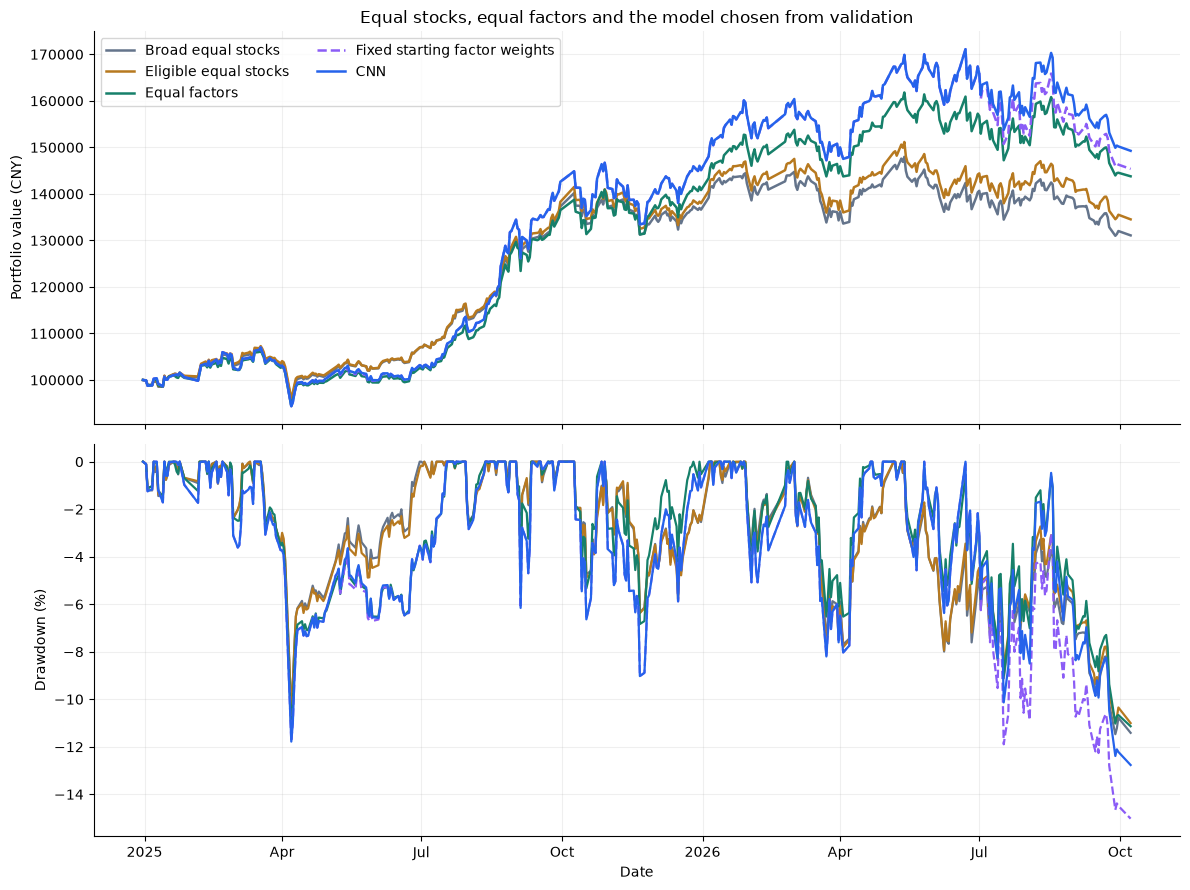

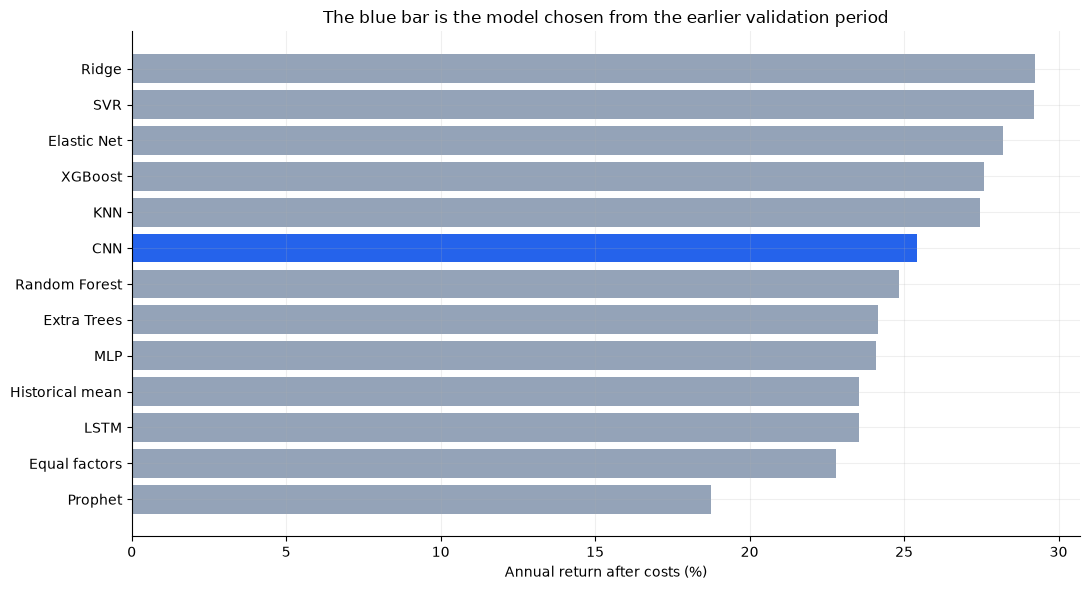

In [20]:
MAIN_LINES = ['Broad equal stocks', 'Eligible equal stocks', 'Equal factors', 'Fixed starting factor weights', chosen_model]
COLORS = ['#64748b', '#b7791f', '#16806a', '#8b5cf6', '#2563eb']
fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
for name, colour in zip(MAIN_LINES, COLORS):
    style = '--' if name == 'Fixed starting factor weights' else '-'
    axes[0].plot(portfolio_values.index, portfolio_values[name], label=name, color=colour, linestyle=style, linewidth=1.8)
    axes[1].plot(portfolio_values.index, (portfolio_values[name] / portfolio_values[name].cummax() - 1) * 100, label=name, color=colour, linestyle=style, linewidth=1.6)
axes[0].set_ylabel('Portfolio value (CNY)')
axes[0].set_title('Equal stocks, equal factors and the model chosen from validation')
axes[0].legend(ncol=2)
axes[1].set_ylabel('Drawdown (%)')
axes[1].set_xlabel('Date')
locator = AutoDateLocator()
axes[1].xaxis.set_major_locator(locator)
axes[1].xaxis.set_major_formatter(ConciseDateFormatter(locator))
fig.tight_layout()
fig.savefig(RESULTS / 'main_comparison.png', dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(11, 6))
ordered = performance.set_index('strategy').loc[['Equal factors', 'Historical mean'] + LEARNED_MODELS].sort_values('annual_return')
bar_colours = ['#2563eb' if name == chosen_model else '#94a3b8' for name in ordered.index]
ax.barh(ordered.index, ordered.annual_return, color=bar_colours)
ax.axvline(0, color='#334155', linewidth=0.7)
ax.set_xlabel('Annual return after costs (%)')
ax.set_title('The blue bar is the model chosen from the earlier validation period')
fig.tight_layout()
fig.savefig(RESULTS / 'model_returns.png', dpi=180)
plt.show()

In [21]:
accuracy_rows = []
for model in ['Historical mean'] + LEARNED_MODELS + ['Always Up']:
    frame = evaluation_predictions.loc[evaluation_predictions.model.eq('Historical mean' if model == 'Always Up' else model)]
    actual = frame.actual_return.gt(0).to_numpy()
    predicted = np.ones(len(frame), dtype=bool) if model == 'Always Up' else frame.predicted_return.gt(0).to_numpy()
    accuracy_rows.append({'model': model, 'accuracy': np.mean(predicted == actual) * 100, 'balanced_accuracy': balanced_accuracy_score(actual, predicted) * 100, 'predicted_up': int(predicted.sum()), 'actual_up': int(actual.sum()), 'forecasts': len(frame), 'mae': np.nan if model == 'Always Up' else (frame.predicted_return - frame.actual_return).abs().mean()})
accuracy = pd.DataFrame(accuracy_rows)
accuracy.to_csv(RESULTS / 'forecast_accuracy.csv', index=False)
display(accuracy)
last_signal = test_signals[-1]
latest = evaluation_predictions.loc[evaluation_predictions.signal.eq(last_signal) & evaluation_predictions.model.eq(chosen_model), ['factor', 'predicted_return', 'actual_return']]
display(latest)

,model,accuracy,balanced_accuracy,predicted_up,actual_up,forecasts,mae
0,Historical mean,65.079,50.000,63,41,63,0.044
1,Ridge,58.730,54.601,41,41,63,0.057
2,Elastic Net,57.143,55.488,36,41,63,0.061
3,KNN,57.143,47.062,52,41,63,0.046
4,SVR,60.317,61.086,32,41,63,0.048
5,Random Forest,63.492,50.887,58,41,63,0.045
6,Extra Trees,63.492,49.834,60,41,63,0.046
7,XGBoost,63.492,59.313,42,41,63,0.045
8,MLP,46.032,41.685,39,41,63,0.062
9,LSTM,65.079,50.000,63,41,63,0.045


,factor,predicted_return,actual_return
1451,Momentum,0.047,-0.077
1450,Profitability,0.010,-0.063
1449,Value,0.002,-0.032


CNN gets the return direction right in 50.79% of the factor forecasts. Always Up gets 65.08%. The model forecasts a rise in 50 of 63 cases. Its average absolute forecast error is 4.92 percentage points, compared with 4.43 for the historical-mean forecast. The portfolio uses the order of the three forecasts, so direction accuracy and portfolio return answer different questions. The final table shows a completed historical prediction and its result.

In [22]:
DEFINITION_PAIRS = [('Value', 'Book to market'), ('Profitability', 'EBIT to book equity'), ('Momentum', 'Ordinary momentum')]
comparison_rows = []
comparison_curves = {}
comparison_counts = []
for factor, alternative in DEFINITION_PAIRS:
    matched_targets = {'Main measure': {}, 'Alternative measure': {}}
    for signal in test_signals:
        scores = score_tables[signal]
        matched = scores.loc[scores.eligible & np.isfinite(scores[alternative])].copy()
        if len(matched) < MIN_ELIGIBLE:
            raise ValueError('Too few matched companies for the factor definition comparison.')
        comparison_counts.append({'signal': signal, 'factor': factor, 'companies': len(matched)})
        count = int(math.ceil(len(matched) * TOP_FRACTION))
        for measure in ['Main measure', 'Alternative measure']:
            comparison_scores = matched[FACTORS].copy()
            if measure == 'Alternative measure':
                comparison_scores[factor] = matched[alternative]
            comparison_baskets = pd.DataFrame(0.0, index=STOCKS, columns=FACTORS)
            for column in FACTORS:
                selected_stocks = comparison_scores[column].sort_values(ascending=False, kind='stable').head(count).index
                comparison_baskets.loc[selected_stocks, column] = 1 / count
            matched_targets[measure][signal] = comparison_baskets.mean(axis=1)
    for measure, targets in matched_targets.items():
        start = evaluation_start
        end = evaluation_end
        simulation_cost = TRADING_COST
        position = calendar.get_loc(start)
        base = calendar[position - 1] if position > 0 else start
        dates = calendar[(calendar >= base) & (calendar <= end)]
        schedule = {entries[signal]: weights.reindex(STOCKS, fill_value=0).to_numpy(float) for signal, weights in targets.items() if signal in entries and start <= entries[signal] <= end}
        holdings = np.zeros(len(STOCKS))
        cash = INITIAL_VALUE
        values = []
        trades = []
        trade_details = []
        actual_weights = []
        previous = None
        for day in dates:
            if previous is not None:
                relative = prices.loc[day].to_numpy(float) / prices.loc[previous].to_numpy(float)
                if not np.isfinite(relative[holdings > 0]).all():
                    raise ValueError('A held stock has no valuation price.')
                holdings *= np.where(np.isfinite(relative), relative, 1.0)
            before = cash + holdings.sum()
            if day in schedule:
                target = schedule[day]
                if (target < -1e-12).any() or not np.isclose(target.sum(), 1):
                    raise ValueError('Long-only target weights must add to one.')
                can_trade = tradable.loc[day].to_numpy(bool)
                frozen = holdings[~can_trade].sum()
                pool = before - frozen
                positive = target[can_trade]
                ratio = positive / positive.sum() if positive.sum() else np.zeros_like(positive)
                before_holdings = holdings.copy()
                prior = holdings[can_trade].copy()
                charge = 0.0
                for iteration in range(100):
                    proposed = ratio * max(pool - charge, 0)
                    new_charge = simulation_cost * np.abs(proposed - prior).sum()
                    if abs(new_charge - charge) < 1e-9:
                        charge = new_charge
                        break
                    charge = new_charge
                proposed = ratio * max(pool - charge, 0)
                charge = simulation_cost * np.abs(proposed - prior).sum()
                holdings[can_trade] = proposed
                cash = before - holdings.sum() - charge
                if cash < -1e-6:
                    raise ValueError('Trading used more money than the portfolio owns.')
                cash = max(cash, 0.0)
                after = cash + holdings.sum()
                traded = np.abs(proposed - prior).sum()
                trades.append({'date': day, 'cost': charge, 'turnover': traded / before, 'frozen_value': frozen, 'cash': cash, 'value_before': before, 'value_after': after, 'unavailable_target_count': int(((target > 0) & ~can_trade).sum())})
                for stock_index, stock in enumerate(STOCKS):
                    change = holdings[stock_index] - before_holdings[stock_index]
                    if abs(change) > 1e-8:
                        trade_details.append({'date': day, 'code': stock, 'before_value': before_holdings[stock_index], 'after_value': holdings[stock_index], 'trade_value': change, 'cost': abs(change) * simulation_cost, 'had_quote': bool(observed.loc[day, stock] > 0 and raw_observed.loc[day, stock] > 0), 'had_volume': bool(volumes.loc[day, stock] > 0)})
                for stock, weight in zip(STOCKS, holdings / after):
                    if weight > 0:
                        actual_weights.append({'date': day, 'code': stock, 'weight': weight})
            value = cash + holdings.sum()
            if value <= 0 or not np.isfinite(value):
                raise ValueError('The portfolio value is invalid.')
            values.append({'date': day, 'value': value, 'cash': cash})
            previous = day
        curve = pd.DataFrame(values).set_index('date')
        trades = pd.DataFrame(trades)
        held = pd.DataFrame(actual_weights)
        years = (curve.index[-1] - curve.index[0]).days / 365.25
        returns = curve.value.pct_change(fill_method=None).dropna()
        volatility = returns.std(ddof=1) * np.sqrt(252)
        statistics = {
            'annual_return': ((curve.value.iloc[-1] / curve.value.iloc[0]) ** (1 / years) - 1) * 100,
            'volatility': volatility * 100,
            'sharpe': returns.mean() / returns.std(ddof=1) * np.sqrt(252),
            'drawdown': (curve.value / curve.value.cummax() - 1).min() * 100,
            'total_return': (curve.value.iloc[-1] / curve.value.iloc[0] - 1) * 100,
            'final_value': curve.value.iloc[-1],
            'costs': trades.cost.sum(),
        }
        comparison_curves[f'{factor}: {measure}'] = curve.value
        comparison_rows.append({'factor': factor, 'measure': measure, 'alternative': alternative, **statistics})
definition_comparison = pd.DataFrame(comparison_rows)
definition_comparison.to_csv(RESULTS / 'factor_comparisons.csv', index=False)
pd.DataFrame(comparison_counts).to_csv(RESULTS / 'factor_comparison_coverage.csv', index=False)
pd.DataFrame(comparison_curves).to_csv(RESULTS / 'factor_comparison_values.csv', index_label='date')
display(definition_comparison)


,factor,measure,alternative,annual_return,volatility,sharpe,drawdown,total_return,final_value,costs
0,Value,Main measure,Book to market,22.789,18.141,1.278,-11.287,43.779,"143,778.819",841.125
1,Value,Alternative measure,Book to market,19.561,17.600,1.153,-10.769,37.160,"137,159.967",780.414
2,Profitability,Main measure,EBIT to book equity,22.789,18.141,1.278,-11.287,43.779,"143,778.819",841.125
3,Profitability,Alternative measure,EBIT to book equity,20.537,17.570,1.203,-11.268,39.147,"139,147.187",831.450
4,Momentum,Main measure,Ordinary momentum,22.789,18.141,1.278,-11.287,43.779,"143,778.819",841.125
5,Momentum,Alternative measure,Ordinary momentum,23.570,18.791,1.276,-12.071,45.398,"145,398.261",788.376


The equal-factor portfolio returns 22.79% a year with EBIT divided by enterprise value and 19.56% when we replace Value with Book to market. The equal-factor portfolio returns 22.79% a year with EBIT divided by average invested capital and 20.54% when we replace Profitability with EBIT to book equity. The equal-factor portfolio returns 22.79% a year with momentum divided by volatility and 23.57% when we replace Momentum with Ordinary momentum. These are returns for the whole three-factor portfolio. We change one measure at a time. Both sides use the same companies and equal factor weights.

,strategy,cost_rate,annual_return,volatility,sharpe,drawdown,total_return,final_value,costs
0,Eligible equal stocks,0.000,18.427,16.005,1.189,-10.966,34.868,"134,867.915",0.000
1,Equal factors,0.000,23.250,18.142,1.300,-11.260,44.735,"144,734.512",0.000
2,Fixed starting factor weights,0.000,24.094,21.168,1.176,-14.914,46.491,"146,491.002",0.000
3,CNN,0.000,26.008,20.942,1.263,-12.632,50.511,"150,511.301",0.000
4,Eligible equal stocks,0.001,18.257,16.003,1.180,-11.003,34.526,"134,526.008",302.876
5,Equal factors,0.001,22.789,18.141,1.278,-11.287,43.779,"143,778.819",841.125
6,Fixed starting factor weights,0.001,23.556,21.168,1.154,-15.025,45.370,"145,369.775","1,003.341"
7,CNN,0.001,25.414,20.942,1.239,-12.767,49.259,"149,258.602","1,089.778"
8,Eligible equal stocks,0.003,17.918,16.001,1.161,-11.077,33.845,"133,845.358",905.666
9,Equal factors,0.003,21.873,18.141,1.235,-11.388,41.887,"141,887.129","2,504.428"


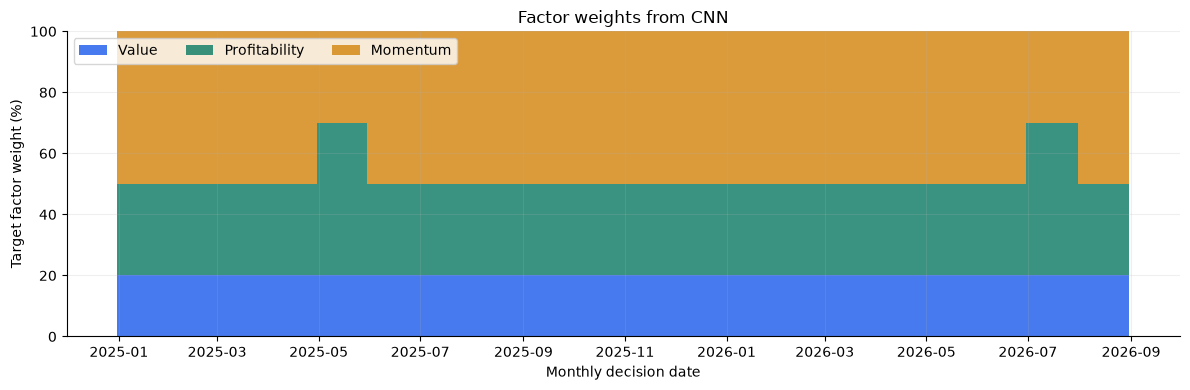

In [23]:
COST_RATES = [0.0, 0.001, 0.003]
cost_rows = []
for rate in COST_RATES:
    for name in ['Eligible equal stocks', 'Equal factors', 'Fixed starting factor weights', chosen_model]:
        targets = targets_by_strategy[name]
        start = evaluation_start
        end = evaluation_end
        simulation_cost = rate
        position = calendar.get_loc(start)
        base = calendar[position - 1] if position > 0 else start
        dates = calendar[(calendar >= base) & (calendar <= end)]
        schedule = {entries[signal]: weights.reindex(STOCKS, fill_value=0).to_numpy(float) for signal, weights in targets.items() if signal in entries and start <= entries[signal] <= end}
        holdings = np.zeros(len(STOCKS))
        cash = INITIAL_VALUE
        values = []
        trades = []
        trade_details = []
        actual_weights = []
        previous = None
        for day in dates:
            if previous is not None:
                relative = prices.loc[day].to_numpy(float) / prices.loc[previous].to_numpy(float)
                if not np.isfinite(relative[holdings > 0]).all():
                    raise ValueError('A held stock has no valuation price.')
                holdings *= np.where(np.isfinite(relative), relative, 1.0)
            before = cash + holdings.sum()
            if day in schedule:
                target = schedule[day]
                if (target < -1e-12).any() or not np.isclose(target.sum(), 1):
                    raise ValueError('Long-only target weights must add to one.')
                can_trade = tradable.loc[day].to_numpy(bool)
                frozen = holdings[~can_trade].sum()
                pool = before - frozen
                positive = target[can_trade]
                ratio = positive / positive.sum() if positive.sum() else np.zeros_like(positive)
                before_holdings = holdings.copy()
                prior = holdings[can_trade].copy()
                charge = 0.0
                for iteration in range(100):
                    proposed = ratio * max(pool - charge, 0)
                    new_charge = simulation_cost * np.abs(proposed - prior).sum()
                    if abs(new_charge - charge) < 1e-9:
                        charge = new_charge
                        break
                    charge = new_charge
                proposed = ratio * max(pool - charge, 0)
                charge = simulation_cost * np.abs(proposed - prior).sum()
                holdings[can_trade] = proposed
                cash = before - holdings.sum() - charge
                if cash < -1e-6:
                    raise ValueError('Trading used more money than the portfolio owns.')
                cash = max(cash, 0.0)
                after = cash + holdings.sum()
                traded = np.abs(proposed - prior).sum()
                trades.append({'date': day, 'cost': charge, 'turnover': traded / before, 'frozen_value': frozen, 'cash': cash, 'value_before': before, 'value_after': after, 'unavailable_target_count': int(((target > 0) & ~can_trade).sum())})
                for stock_index, stock in enumerate(STOCKS):
                    change = holdings[stock_index] - before_holdings[stock_index]
                    if abs(change) > 1e-8:
                        trade_details.append({'date': day, 'code': stock, 'before_value': before_holdings[stock_index], 'after_value': holdings[stock_index], 'trade_value': change, 'cost': abs(change) * simulation_cost, 'had_quote': bool(observed.loc[day, stock] > 0 and raw_observed.loc[day, stock] > 0), 'had_volume': bool(volumes.loc[day, stock] > 0)})
                for stock, weight in zip(STOCKS, holdings / after):
                    if weight > 0:
                        actual_weights.append({'date': day, 'code': stock, 'weight': weight})
            value = cash + holdings.sum()
            if value <= 0 or not np.isfinite(value):
                raise ValueError('The portfolio value is invalid.')
            values.append({'date': day, 'value': value, 'cash': cash})
            previous = day
        curve = pd.DataFrame(values).set_index('date')
        trades = pd.DataFrame(trades)
        held = pd.DataFrame(actual_weights)
        years = (curve.index[-1] - curve.index[0]).days / 365.25
        returns = curve.value.pct_change(fill_method=None).dropna()
        volatility = returns.std(ddof=1) * np.sqrt(252)
        statistics = {
            'annual_return': ((curve.value.iloc[-1] / curve.value.iloc[0]) ** (1 / years) - 1) * 100,
            'volatility': volatility * 100,
            'sharpe': returns.mean() / returns.std(ddof=1) * np.sqrt(252),
            'drawdown': (curve.value / curve.value.cummax() - 1).min() * 100,
            'total_return': (curve.value.iloc[-1] / curve.value.iloc[0] - 1) * 100,
            'final_value': curve.value.iloc[-1],
            'costs': trades.cost.sum(),
        }
        cost_rows.append({'strategy': name, 'cost_rate': rate, **statistics})
cost_results = pd.DataFrame(cost_rows)
cost_results.to_csv(RESULTS / 'cost_comparison.csv', index=False)
display(cost_results)

weights = factor_weights.loc[factor_weights.model.eq(chosen_model)].set_index('signal')[FACTORS]
fig, ax = plt.subplots(figsize=(12, 4))
ax.stackplot(weights.index, *[weights[name] * 100 for name in FACTORS], labels=FACTORS, colors=['#2563eb', '#16806a', '#d58a18'], step='post', alpha=0.85)
ax.set_ylim(0, 100)
ax.set_ylabel('Target factor weight (%)')
ax.set_xlabel('Monthly decision date')
ax.set_title(f'Factor weights from {chosen_model}')
ax.legend(loc='upper left', ncol=3)
fig.tight_layout()
fig.savefig(RESULTS / 'factor_weights.png', dpi=180)
plt.show()

For CNN, the annual return is 26.01% without trading charges, 25.41% with a 0.10% charge and 24.23% with a 0.30% charge on each amount bought or sold. We keep the same forecasts and target weights in these runs. The factor-weight chart shows how the model divides the money between Value, Profitability and Momentum.

In [24]:
coverage = companies.copy()
coverage['exchange'] = coverage.ticker.str.rsplit('.', n=1).str[-1]
coverage['price_start'] = coverage.code.map(price_rows.groupby('code').date.min())
coverage['price_end'] = coverage.code.map(price_rows.groupby('code').date.max())
coverage['financial_count'] = coverage.code.map(financials.groupby('code').size()).fillna(0).astype(int)
evaluation_scores = score_history.loc[score_history.signal.isin(test_signals)]
coverage['eligible_months'] = coverage.code.map(evaluation_scores.groupby('code').eligible.sum()).fillna(0).astype(int)
coverage['eligible'] = coverage.code.map(score_tables[last_signal].eligible).fillna(False)
coverage['status'] = coverage.code.map(score_tables[last_signal].reason)
coverage.to_csv(RESULTS / 'coverage.csv', index=False)
summary = {
    'candidate_count': len(STOCKS), 'eligible_count': int(score_tables[last_signal].eligible.sum()),
    'eligible_min': int(evaluation_scores.groupby('signal').eligible.sum().min()),
    'eligible_max': int(evaluation_scores.groupby('signal').eligible.sum().max()),
    'price_start': price_rows.date.min().strftime('%Y-%m-%d'), 'price_end': price_rows.date.max().strftime('%Y-%m-%d'),
    'test_start': evaluation_start.strftime('%Y-%m-%d'), 'test_end': evaluation_end.strftime('%Y-%m-%d'),
    'valuation_base': portfolio_values.index[0].strftime('%Y-%m-%d'), 'monthly_periods': len(test_signals),
    'validation_months': len(validation_signals), 'validation_start': samples.loc[validation_signals].entry.min().strftime('%Y-%m-%d'),
    'selection_end': samples.loc[validation_signals].exit.max().strftime('%Y-%m-%d'),
    'cost_rate': TRADING_COST, 'initial_value': INITIAL_VALUE, 'chosen_model': chosen_model,
    'selected_validation_mae': float(selection.loc[selection.selected, 'validation_mae'].iloc[0]),
    'min_training_months': MIN_TRAINING, 'model_count': len(LEARNED_MODELS),
    'first_validation_training_months': int(training_audit.loc[training_audit.split.eq('validation'), 'training_months'].iloc[0]),
    'first_evaluation_training_months': int(training_audit.loc[training_audit.split.eq('evaluation'), 'training_months'].iloc[0]),
    'factor_history_start': first_entry.strftime('%Y-%m-%d'),
    'first_training_signal': sample_signals[0].strftime('%Y-%m-%d'),
    'financial_company_count': int(companies.is_financial.sum()), 'top_fraction': TOP_FRACTION,
    'last_signal': last_signal.strftime('%Y-%m-%d'), 'cash_rate': 0.0,
    'fixed_value_weight': fixed_allocation['Value'],
    'fixed_profitability_weight': fixed_allocation['Profitability'],
    'fixed_momentum_weight': fixed_allocation['Momentum'],
    'fixed_starting_annual_return': float(performance.loc[performance.strategy.eq('Fixed starting factor weights'), 'annual_return'].iloc[0]),
    'dynamic_vs_fixed_gap': float(performance.loc[performance.strategy.eq(chosen_model), 'annual_return'].iloc[0] - performance.loc[performance.strategy.eq('Fixed starting factor weights'), 'annual_return'].iloc[0]),
    'different_from_start_months': int((factor_weights.loc[factor_weights.model.eq(chosen_model), FACTORS].sub(fixed_allocation).abs().sum(axis=1) > 1e-10).sum()),
}
pd.DataFrame(list(summary.items()), columns=['item', 'value']).to_csv(RESULTS / 'data_summary.csv', index=False)
methods = pd.DataFrame([
    ['Question', 'Does factor selection help, and does ML improve monthly allocation between factors?'],
    ['Decision and trade', 'Last monthly trading close; execute at the next trading close.'],
    ['Accounting', 'Annual EBIT; available after announcement and no earlier than 30 June after that financial year.'],
    ['Value', 'EBIT / (raw A-share price * total ordinary shares + funded debt + minority equity - cash).'],
    ['Profitability', 'EBIT / average opening and closing (total equity + funded debt - cash).'],
    ['Momentum', 'Twelve-to-one-month price return / annualized daily volatility over twelve months.'],
    ['Eligibility', 'Nonfinancial company; current trading quote; twelve months of history with at least 160 observed trading quotes; available annual statements no more than eighteen months old.'],
    ['Portfolio', 'Top quarter per factor, rounded up; equal weights inside each basket; monthly rebalancing.'],
    ['ML allocation', '50%, 30%, 20% ordered by predicted next-month factor returns.'],
    ['Fixed-weight diagnostic', 'Hold the chosen model first-decision factor weights throughout evaluation; stock baskets still rebalance monthly. No weights are chosen from evaluation returns.'],
    ['Trading gaps', 'No trading without a current quote; retain held positions; rescale tradable targets to remaining funds.'],
    ['Training', 'Expanding historical sample; only labels completed by the signal date; no random time shuffle.'],
    ['Selection', 'Lowest validation MAE across three factor returns; test returns are not used to choose a model.'],
    ['Costs', '0.10% per amount bought or sold, including initial purchases; zero cash yield.'],
    ['Price data', 'Provider-adjusted closes for return proxies and raw closes for market value.'],
    ['Scope', 'Retrospective study of the selected 100 A-share companies; vendor accounts can include later revisions.'],
], columns=['item', 'detail'])
methods.to_csv(RESULTS / 'methods.csv', index=False)
checks = {
    '100_unique_companies': len(STOCKS) == len(set(STOCKS)) == 100,
    'same_curve_dates': not portfolio_values.isna().any().any(),
    'same_initial_value': bool(np.allclose(portfolio_values.iloc[0], INITIAL_VALUE)),
    'positive_portfolio_values': bool(portfolio_values.gt(0).all().all()),
    'all_models_all_months': len(evaluation_predictions) == len(test_signals) * 3 * 12,
    'training_finished_before_signal': bool(training_audit.last_training_exit.le(training_audit.signal).all()),
    'accounts_known_by_signal': bool(used.available_date.le(used.signal).all()),
    'factor_weights_sum_to_one': bool(np.allclose(factor_weights[FACTORS].sum(axis=1), 1.0)),
    'no_negative_cash': bool(pd.concat(cash_rows).cash.ge(-1e-6).all()),
}
pd.DataFrame(list(checks.items()), columns=['check', 'passed']).to_csv(RESULTS / 'checks.csv', index=False)
if not all(checks.values()):
    raise ValueError('A result check failed.')
display(pd.DataFrame(list(summary.items()), columns=['item', 'value']))

,item,value
0,candidate_count,100
1,eligible_count,94
2,eligible_min,90
3,eligible_max,94
4,price_start,2015-01-05
5,price_end,2026-10-16
6,test_start,2025-01-02
7,test_end,2026-10-08
8,valuation_base,2024-12-31
9,monthly_periods,21


We use these questions to explain our results. We compare 21 completed monthly holding periods from 2 January 2025 to 8 October 2026. All returns below are annualized and include trading costs.

Does selecting stocks with factors give a higher return than equal stock weights?

Yes, in our test. Equal weights in the eligible stocks give a return of 18.26% a year. Selecting stocks with Value, Profitability and Momentum, with one-third of the money in each factor, gives 22.79%. This is 4.53 percentage points more. We compare both portfolios over the same dates.

Does using ML to change factor weights add more return?

Yes, for CNN in this test. We chose CNN because it had the lowest forecast error in the earlier validation period. Its return is 25.41%, compared with 22.79% for equal factor weights. This is 2.62 percentage points more. We also keep its first factor weights fixed at 20% Value, 30% Profitability and 50% Momentum. This gives 23.56%. Stocks inside the factors still change monthly. The CNN rule gives 1.86 percentage points more than these fixed weights. Its factor weights differ from the starting weights in 2 of the 21 months.

Does CNN also reduce risk compared with equal factor weights?

The largest fall from an earlier portfolio high is 12.77% for CNN and 11.29% for equal factors. The Sharpe ratio is 1.24 for CNN and 1.28 for equal factors. Equal factor weights have a higher Sharpe ratio. We use this ratio to compare return with the risk taken.

Does CNN predict the direction of factor returns more accurately?

CNN gets the direction right in 50.79% of the 63 factor forecasts. Always predicting a rise gives 65.08%. So CNN is less accurate than that simple prediction in this test. We use the order of the three forecasts to set portfolio weights. A higher portfolio return does not mean that more Up or Down forecasts are correct.

What is our answer to the research question?

We find that selecting stocks with the three factors gives a higher return than equal stock weights. Changing factor weights with CNN gives 2.62 percentage points more annual return than equal factor weights. The CNN allocation does not improve the Sharpe ratio compared with equal factor weights. We therefore report return, risk and prediction accuracy separately. This answer describes our selected company group and the 21 monthly periods we tested.